# Eurovision: predicting the points with all features

We predict how many points one country gives another country's song in a final (`points`, 0–12), for every final from 2008 to 2026. Adding up the predicted points of a song gives a predicted scoreboard, so the model also predicts the winner.

Steps:
1. Load `features_full.csv`, make one score per country pair, and choose the features.
2. Split into train / validation / test sets.
3. Linear regression, random forest with different parameters, lasso.
4. Find the useless features and remove them.
5. Pick the best model on the validation set and predict the test set.
6. Summary.

In [1]:
%pip install pandas numpy scikit-learn matplotlib

~/.cache/uv/builds-v0/.tmp2f42BK/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LassoCV, LinearRegression
from sklearn.model_selection import GroupKFold, ParameterGrid
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("features_full.csv", low_memory=False)
print(df.shape)
print(df.groupby("year")["vote_type"].unique())

(27918, 35)
year
2008                    [combined]
2009                    [combined]
2010                    [combined]
2011                    [combined]
2012                    [combined]
2013                    [combined]
2014                    [combined]
2015                    [combined]
2016              [jury, televote]
2017              [televote, jury]
2018              [jury, televote]
2019              [jury, televote]
2021              [jury, televote]
2022              [jury, televote]
2023    [jury, televote, combined]
2024              [jury, televote]
2025              [jury, televote]
2026              [televote, jury]
Name: vote_type, dtype: object


## 1. One score per country pair

The voting rules changed in 2016:
- **2008–2015**: every country gives **one** set of points (jury and public already merged), `vote_type` = `combined`.
- **2016–2026**: every country gives **two** sets of points, one from the jury and one from the public.

To compare all years we take the **average of jury and public** from 2016 on. Then every year has one score per pair from 0 to 12, like before 2016. All the other columns are the same in the jury row and the public row of a pair, so we just keep the first one.

In 2023 there are 26 extra `combined` rows: the "rest of the world" online vote, which is not a country. We drop them.

In [3]:
df = df[(df["year"] < 2016) | (df["vote_type"] != "combined")]

keys = ["year", "from_iso3", "to_iso3"]
others = {column: "first" for column in df.columns if column not in keys + ["points"]}
df = df.groupby(keys, as_index=False).agg({"points": "mean", **others})
print(df.shape)
df.head()

(18043, 35)


,year,from_iso3,to_iso3,points,censored,colony,comcol,comlang_ethno,comlang_off,contig,...,sentiment,separately_reported,smctry,televote_share,theme,vote_type,web_interest,youtube_interest,artist_age,artist_sex
0,2008,ALB,ARM,2.0,True,False,False,False,False,False,...,neutral,False,False,1.0,romance,combined,0.0,0.0,21.0,female
1,2008,ALB,AZE,0.0,True,False,False,False,False,False,...,neutral,False,False,1.0,society,combined,0.0,0.0,NaN,NaN
2,2008,ALB,BIH,0.0,True,False,False,False,False,False,...,funny,False,False,1.0,romance,combined,0.0,0.0,NaN,NaN
3,2008,ALB,DEU,0.0,True,False,False,False,False,False,...,sad,False,False,1.0,heartbreak,combined,0.0,0.0,NaN,NaN
4,2008,ALB,DNK,0.0,True,False,False,False,False,False,...,neutral,False,False,1.0,festivity,combined,0.0,0.0,25.0,male


## 2. Features

Not every column can be used. Some only identify the row, some are the same in every row, and some are **computed from the result itself**, so they would not be known before the final (using them would be cheating).

In [4]:
TARGET = "points"

# identify the row, not features
IDS = ["entry_id", "from_iso3", "to_iso3", "year"]
# jury or public, gone after taking the average above
VOTE = ["vote_type"]
# computed from the points of the final, unknown before the final
LEAKS = ["points_received_total", "points_share", "receiver_effect"]
# the same value in every row, or the same for every song of a final (voting rules)
CONSTANT = ["round", "jury_share", "televote_share", "separately_reported", "row_vote"]
# same information as log_dist
DUPLICATES = ["dist", "distw"]

NUMERIC = ["log_dist", "past_points", "past_meetings", "web_interest", "youtube_interest",
           "running_position", "artist_age"]
YES_NO = ["contig", "comlang_off", "comlang_ethno", "colony", "comcol", "smctry", "censored",
          "repetition_verse", "repetition_chorus"]
CATEGORIES = ["sentiment", "theme", "artist_sex"]

# yes/no columns as 1/0, categories as one 0/1 column per value
X = df[NUMERIC].astype(float)
for column in YES_NO:
    X[column] = df[column].map({True: 1, False: 0, "True": 1, "False": 0}).astype(float)
# bands have no sex, 2010 has no lyrics
missing = {"artist_sex": "band or unknown", "sentiment": "unknown", "theme": "unknown"}
X = pd.concat([X, pd.get_dummies(df[CATEGORIES].fillna(missing), dtype=float)], axis=1)
y = df[TARGET]

print(X.shape[1], "features:", list(X.columns))

33 features: ['log_dist', 'past_points', 'past_meetings', 'web_interest', 'youtube_interest', 'running_position', 'artist_age', 'contig', 'comlang_off', 'comlang_ethno', 'colony', 'comcol', 'smctry', 'censored', 'repetition_verse', 'repetition_chorus', 'sentiment_funny', 'sentiment_neutral', 'sentiment_sad', 'sentiment_unknown', 'theme_festivity', 'theme_folklore', 'theme_heartbreak', 'theme_kinship', 'theme_nature', 'theme_other', 'theme_romance', 'theme_society', 'theme_unknown', 'artist_sex_band or unknown', 'artist_sex_female', 'artist_sex_male', 'artist_sex_other']


## 3. Train, validation and test sets

We split **by year**, not randomly. In a random split some votes of the same final would be in the training set and others in the test set, so the model would partly know the answer. Splitting by year is also what a real prediction looks like: we know the past finals, not this one.

| set | finals | used for |
|---|---|---|
| train | 2008–2019 (11 finals, 2020 was cancelled) | fitting the models |
| validation | 2021, 2022, 2023 | choosing parameters and the best model |
| test | 2024, 2025, 2026 | the final check, used only once at the end |

Missing values are filled with the median of the **training** set. Note: 2010 has no lyrics and no Google Trends data, so for 2010 those columns are filled with the median too.

In [5]:
TRAIN = [2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019]
VAL = [2021, 2022, 2023]
TEST = [2024, 2025, 2026]

train = df["year"].isin(TRAIN)
val = df["year"].isin(VAL)
test = df["year"].isin(TEST)

medians = X[train].median()
X = X.fillna(medians)

X_train, y_train = X[train], y[train]
X_val, y_val = X[val], y[val]
X_test, y_test = X[test], y[test]
print("train / val / test rows:", len(y_train), len(y_val), len(y_test))

train / val / test rows: 12382 2899 2762


### How we measure a model
- **R²** on the single votes: how much of the variation in points the model explains (1 = perfect, 0 = no better than always guessing the average).
- **Winner rank**: we add up the predicted points per song and sort, which gives a predicted scoreboard. Then we look at which place the model gave to the real winner (1 = winner predicted correctly).
- **Rank error**: how many places a song is off on average between the predicted and the real scoreboard (0 = perfect). This is the number for the presentation, because everybody understands "places".
- **Chance**: the rank error of a random scoreboard, drawn 1000 times per final. A model is only useful if it is clearly below that.

In [6]:
def winner_rank(rows, predicted):
    """for every final: predicted place of the real winner"""
    board = df.loc[rows, ["year", "to_iso3", "points"]].assign(predicted=predicted)
    board = board.groupby(["year", "to_iso3"], as_index=False)[["points", "predicted"]].sum()
    places = {}
    for year, songs in board.groupby("year"):
        songs = songs.sort_values("predicted", ascending=False).reset_index(drop=True)
        real_winner = songs["points"].idxmax()
        places[year] = real_winner + 1
    return places


def rank_error(rows, predicted):
    """mean distance between predicted and real place, averaged over the finals"""
    board = df.loc[rows, ["year", "to_iso3", "points"]].assign(predicted=predicted)
    board = board.groupby(["year", "to_iso3"], as_index=False)[["points", "predicted"]].sum()
    errors = []
    for year, songs in board.groupby("year"):
        real = songs["points"].rank(ascending=False, method="min")
        guess = songs["predicted"].rank(ascending=False, method="min")
        errors.append((real - guess).abs().mean())
    return float(np.mean(errors))


def chance(rows, draws=1000, seed=0):
    """rank error of a random scoreboard: mean and 95 % range over the draws"""
    rng = np.random.default_rng(seed)
    board = df.loc[rows].groupby(["year", "to_iso3"], as_index=False)["points"].sum()
    per_final = []
    for year, songs in board.groupby("year"):
        real = songs["points"].rank(ascending=False, method="min").to_numpy()
        per_final.append([np.abs(real - rng.permutation(real)).mean() for _ in range(draws)])
    errors = np.mean(per_final, axis=0)
    return errors.mean(), np.percentile(errors, 2.5), np.percentile(errors, 97.5)


def report(name, model, X_tr=None, X_va=None):
    X_tr = X_train if X_tr is None else X_tr
    X_va = X_val if X_va is None else X_va
    places = winner_rank(val, model.predict(X_va))
    print(f"{name}")
    print(f"\ttrain R^2 = {model.score(X_tr, y_train):.3f}")
    print(f"\tval R^2   = {model.score(X_va, y_val):.3f}")
    print(f"\trank error = {rank_error(val, model.predict(X_va)):.2f} places")
    print(f"\tpredicted place of the real winner: {places}")
    return model.score(X_va, y_val)


val_scores = {}

mean, low, high = chance(val)
print(f"chance on the validation finals: {mean:.2f} places off (95 % range {low:.2f} to {high:.2f})")

chance on the validation finals: 8.57 places off (95 % range 7.34 to 9.79)


## 4. Linear regression
The features have very different scales (distance, points, 0/1 columns), so we standardise them first. The scaler is fitted on the training set only.

In [7]:
scaler = StandardScaler().fit(X_train)
X_train_s, X_val_s, X_test_s = (scaler.transform(part) for part in (X_train, X_val, X_test))

linear = LinearRegression().fit(X_train_s, y_train)
val_scores["linear regression"] = report("Linear regression", linear, X_train_s, X_val_s)

Linear regression
	train R^2 = 0.240
	val R^2   = 0.065
	rank error = 7.25 places
	predicted place of the real winner: {2021: 4, 2022: 9, 2023: 12}


## 5. Random forest with different parameters
We try every combination below, train on the training set and compare on the validation set (like in the homework). Takes a few minutes.

In [8]:
param_grid = ParameterGrid({
    "n_estimators": [100, 300],
    "max_depth": [4, 6, 10, None],
    "min_samples_leaf": [1, 20, 100],
})

results = []
for params in param_grid:
    model = RandomForestRegressor(random_state=0, n_jobs=-1, **params).fit(X_train, y_train)
    results.append({**params, "val_R2": model.score(X_val, y_val)})
results = pd.DataFrame(results).sort_values("val_R2", ascending=False)
print(results.head(10).to_string(index=False))

 max_depth  min_samples_leaf  n_estimators   val_R2
       NaN               100           100 0.179888
       NaN               100           300 0.178887
      10.0               100           100 0.178547
       4.0               100           100 0.178500
       4.0               100           300 0.177760
      10.0               100           300 0.177057
       4.0                20           100 0.175514
       4.0                20           300 0.173560
       4.0                 1           100 0.173018
       4.0                 1           300 0.171451


In [9]:
best_params = results.iloc[0].drop("val_R2").to_dict()
best_params["n_estimators"] = int(best_params["n_estimators"])
best_params["min_samples_leaf"] = int(best_params["min_samples_leaf"])
best_params["max_depth"] = None if pd.isna(best_params["max_depth"]) else int(best_params["max_depth"])
print("Best parameters:", best_params)

forest = RandomForestRegressor(random_state=0, n_jobs=-1, **best_params).fit(X_train, y_train)
val_scores["random forest"] = report("Random forest", forest)

Best parameters: {'max_depth': None, 'min_samples_leaf': 100, 'n_estimators': 100}


Random forest
	train R^2 = 0.304
	val R^2   = 0.180
	rank error = 5.82 places
	predicted place of the real winner: {2021: 3, 2022: 3, 2023: 2}


## 6. Lasso
Lasso is linear regression that pushes the weights of unhelpful features to exactly zero. The penalty strength is chosen by cross-validation inside the training set, again by year (`GroupKFold`), so no final is split.

In [10]:
folds = list(GroupKFold(n_splits=3).split(X_train_s, y_train, groups=df.loc[train, "year"]))
lasso = LassoCV(cv=folds, random_state=0).fit(X_train_s, y_train)
print(f"chosen penalty alpha = {lasso.alpha_:.4f}")
val_scores["lasso"] = report("Lasso", lasso, X_train_s, X_val_s)

chosen penalty alpha = 0.0800
Lasso
	train R^2 = 0.231
	val R^2   = 0.125
	rank error = 6.91 places
	predicted place of the real winner: {2021: 5, 2022: 6, 2023: 5}


## 7. Which features are useless?
Two views:
- **Lasso coefficient**: 0 means lasso threw the feature away.
- **Random forest importance**: how much the forest uses the feature (all importances add up to 1).

A feature is removed if **both** say it is useless: lasso set it to 0 **and** the forest gives it less than 1 % importance.

In [11]:
features = pd.DataFrame({
    "lasso_coef": lasso.coef_,
    "forest_importance": forest.feature_importances_,
}, index=X.columns).sort_values("forest_importance", ascending=False)

useless = features[(features["lasso_coef"] == 0) & (features["forest_importance"] < 0.01)].index.tolist()
keep = [f for f in X.columns if f not in useless]
print(features.round(4).to_string())
print()
print(f"removed {len(useless)} features:", useless)
print(f"kept {len(keep)} features:", keep)

                            lasso_coef  forest_importance
past_points                     1.1844             0.6454
running_position                0.2726             0.1238
web_interest                    0.1089             0.0626
log_dist                       -0.0461             0.0438
artist_age                     -0.0697             0.0298
theme_heartbreak                0.0289             0.0168
artist_sex_male                 0.1578             0.0166
past_meetings                  -0.0000             0.0124
sentiment_neutral              -0.1345             0.0115
artist_sex_female              -0.0000             0.0105
artist_sex_band or unknown     -0.0000             0.0058
youtube_interest                0.0000             0.0049
censored                       -0.2059             0.0049
sentiment_sad                   0.0252             0.0043
theme_romance                  -0.0000             0.0025
repetition_verse               -0.0000             0.0019
contig        

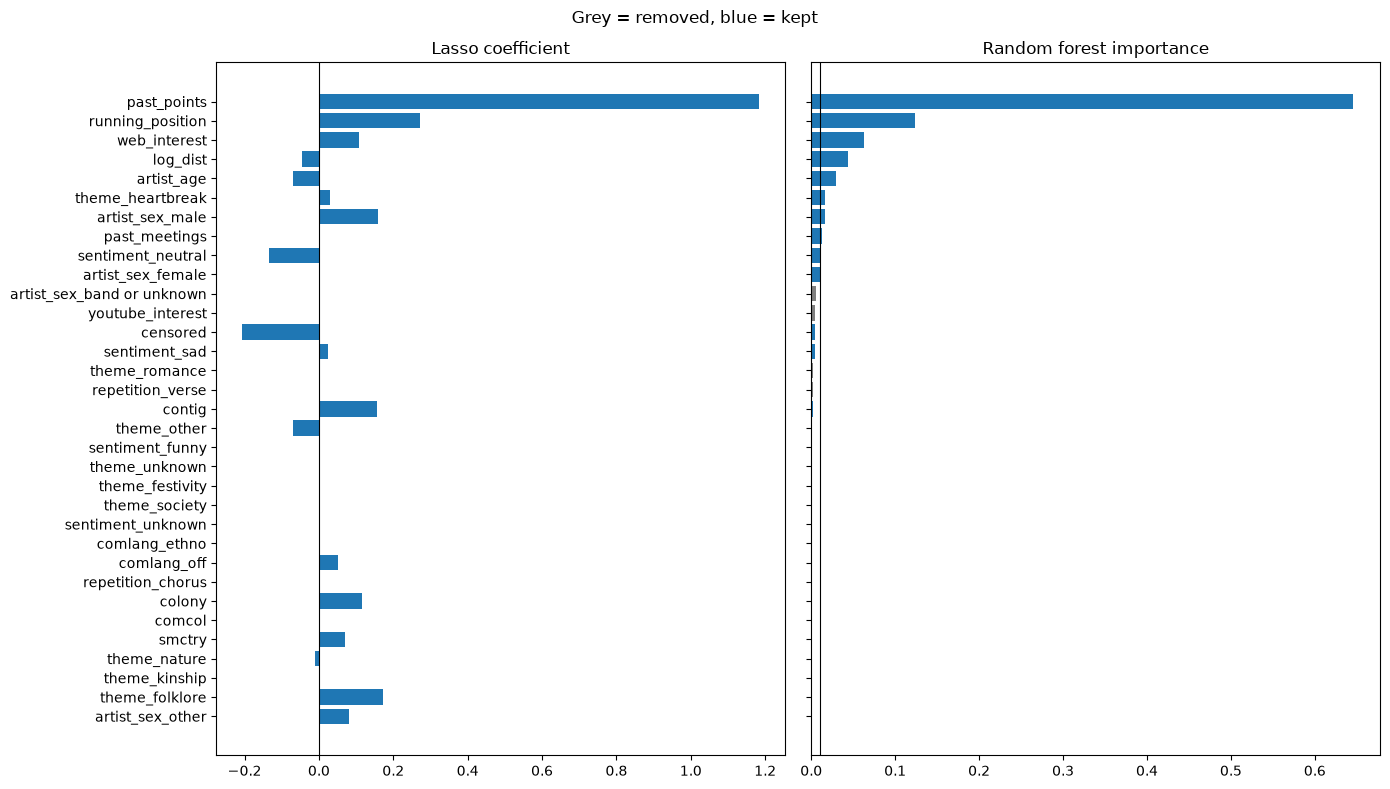

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
order = features.index[::-1]
colors = ["tab:gray" if f in useless else "tab:blue" for f in order]
axes[0].barh(order, features.loc[order, "lasso_coef"], color=colors)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Lasso coefficient")
axes[1].barh(order, features.loc[order, "forest_importance"], color=colors)
axes[1].axvline(0.01, color="black", linewidth=0.8)
axes[1].set_title("Random forest importance")
fig.suptitle("Grey = removed, blue = kept")
plt.tight_layout()
plt.show()

### Do age and sex help? The forest graph against lasso

The importance graph above says the forest uses `artist_age` (3 %) and `artist_sex` (2–3 %). Lasso gives them small weights (`artist_age` −0.07, `artist_sex_male` +0.16). But importance only says how often the forest **splits** on a column, not whether the prediction gets better. A forest also splits on noise, especially on a column like age that has many different values.

The fair test: train the same forest **with and without** a group of features and compare on the validation finals 2021–2023. If the rank error goes down without the group, the group did not help.

In [13]:
groups = {
    "nothing (all features)": [],
    "age and sex": [c for c in X.columns if c.startswith("artist_")],
    "Google searches": ["web_interest", "youtube_interest", "censored"],
    "lyrics": [c for c in X.columns if c.startswith(("sentiment_", "theme_", "repetition_"))],
    "running order": ["running_position"],
    "past points between the countries": ["past_points", "past_meetings"],
}
rows = []
for name, drop in groups.items():
    cols = [c for c in X.columns if c not in drop]
    model = RandomForestRegressor(random_state=0, n_jobs=2, **best_params).fit(X_train[cols], y_train)
    rows.append({"left out": name,
                 "val R2": model.score(X_val[cols], y_val),
                 "val rank error": rank_error(val, model.predict(X_val[cols]))})
ablation = pd.DataFrame(rows).set_index("left out")
print(ablation.round(3).to_string())

                                   val R2  val rank error
left out                                                 
nothing (all features)              0.180           5.819
age and sex                         0.205           5.552
Google searches                     0.139           6.635
lyrics                              0.181           5.718
running order                       0.140           6.677
past points between the countries   0.080           7.213


**Result:** without age and sex the forest gets **better** on the validation finals (rank error 5.82 → 5.55, R² 0.180 → 0.205). So lasso is right and the importance graph is misleading. On the test finals it is the other way round (6.28 with them, 6.64 without, not in this notebook), so the honest answer is: age and sex make no reliable difference. A third of the songs are bands or have no age on Wikidata, which also weakens any effect.

What clearly matters: without the past points between the two countries the error jumps to 7.2, without Google searches or the running order to about 6.6. Lyrics make no difference.

### Do the extra years 2008–2015 help?

Same forest, trained once on 2008–2019 and once only on 2016–2019, both checked on the validation finals. Google Trends is weak in the early years (2008 and 2009 almost all zero, 2010 missing), so this tests whether the extra years are worth it.

In [14]:
recent = (df.loc[train, "year"] >= 2016).to_numpy()
for name, used in [("2008-2019", np.ones(len(y_train), dtype=bool)), ("2016-2019", recent)]:
    model = RandomForestRegressor(random_state=0, n_jobs=2, **best_params).fit(X_train[used], y_train[used])
    print(f"trained on {name}: val R2 = {model.score(X_val, y_val):.3f}, "
          f"val rank error = {rank_error(val, model.predict(X_val)):.2f}")

trained on 2008-2019: val R2 = 0.180, val rank error = 5.82


trained on 2016-2019: val R2 = 0.108, val rank error = 7.12


**Result:** the years 2008–2015 help a lot, even with weak search data: rank error 5.82 with them, 7.12 without. More finals give the forest more examples of how pairs of countries vote.

### The models again, without the useless features

In [15]:
forest_small = RandomForestRegressor(random_state=0, n_jobs=-1, **best_params).fit(X_train[keep], y_train)
val_scores["random forest, fewer features"] = report("Random forest, fewer features", forest_small,
                                                     X_train[keep], X_val[keep])

scaler_small = StandardScaler().fit(X_train[keep])
lasso_small = LassoCV(cv=folds, random_state=0).fit(scaler_small.transform(X_train[keep]), y_train)
val_scores["lasso, fewer features"] = report("Lasso, fewer features", lasso_small,
                                             scaler_small.transform(X_train[keep]),
                                             scaler_small.transform(X_val[keep]))

Random forest, fewer features
	train R^2 = 0.301
	val R^2   = 0.178


	rank error = 5.77 places
	predicted place of the real winner: {2021: 3, 2022: 3, 2023: 2}
Lasso, fewer features
	train R^2 = 0.231
	val R^2   = 0.125
	rank error = 6.91 places
	predicted place of the real winner: {2021: 5, 2022: 6, 2023: 5}


## 8. The best model on the test set
We pick the model with the best validation R². Only now do we look at the test set, once.

In [16]:
print(pd.Series(val_scores).sort_values(ascending=False).round(3).to_string())
best_name = max(val_scores, key=val_scores.get)
print("\nbest model:", best_name)

random forest                    0.180
random forest, fewer features    0.178
lasso, fewer features            0.125
lasso                            0.125
linear regression                0.065

best model: random forest


In [17]:
# the best model and the data it needs
best = {
    "linear regression": (linear, X_train_s, X_test_s),
    "random forest": (forest, X_train, X_test),
    "lasso": (lasso, X_train_s, X_test_s),
    "random forest, fewer features": (forest_small, X_train[keep], X_test[keep]),
    "lasso, fewer features": (lasso_small, scaler_small.transform(X_train[keep]),
                              scaler_small.transform(X_test[keep])),
}
model, X_tr, X_te = best[best_name]
test_pred = model.predict(X_te)

print(f"{best_name}")
print(f"\ttrain R^2 = {model.score(X_tr, y_train):.3f}")
print(f"\ttest R^2  = {model.score(X_te, y_test):.3f}")
print(f"\tpredicted place of the real winner: {winner_rank(test, test_pred)}")
print(f"\trank error = {rank_error(test, test_pred):.2f} places")
mean, low, high = chance(test)
print(f"chance on the test finals: {mean:.2f} places off (95 % range {low:.2f} to {high:.2f})")

random forest
	train R^2 = 0.304
	test R^2  = 0.121
	predicted place of the real winner: {2024: 3, 2025: 6, 2026: 9}
	rank error = 6.28 places
chance on the test finals: 8.42 places off (95 % range 7.16 to 9.57)


In [18]:
# predicted against real top 10 of every test final
board = df.loc[test, ["year", "to_iso3", "points"]].assign(predicted=test_pred)
board = board.groupby(["year", "to_iso3"], as_index=False)[["points", "predicted"]].sum()
board["real place"] = board.groupby("year")["points"].rank(ascending=False, method="min").astype(int)
board["predicted place"] = board.groupby("year")["predicted"].rank(ascending=False, method="first").astype(int)

for year in TEST:
    top = board[board["year"] == year].sort_values("predicted place").head(10)
    print(f"\n{year}")
    print(top[["predicted place", "to_iso3", "predicted", "real place", "points"]]
          .round(0).to_string(index=False))


2024
 predicted place to_iso3  predicted  real place  points
               1     LVA      150.0          16    32.0
               2     FRA      143.0           4   224.0
               3     CHE      135.0           1   298.0
               4     CYP      116.0          15    39.0
               5     IRL      106.0           6   142.0
               6     ITA      106.0           7   134.0
               7     ISR       99.0           5   194.0
               8     ARM       93.0           8    94.0
               9     HRV       92.0           2   278.0
              10     LTU       90.0          14    45.0

2025
 predicted place to_iso3  predicted  real place  points
               1     CHE      159.0          10   107.0
               2     SWE      139.0           4   164.0
               3     FRA      124.0           7   115.0
               4     ITA      124.0           5   128.0
               5     UKR      121.0           9   113.0
               6     AUT      120.0 

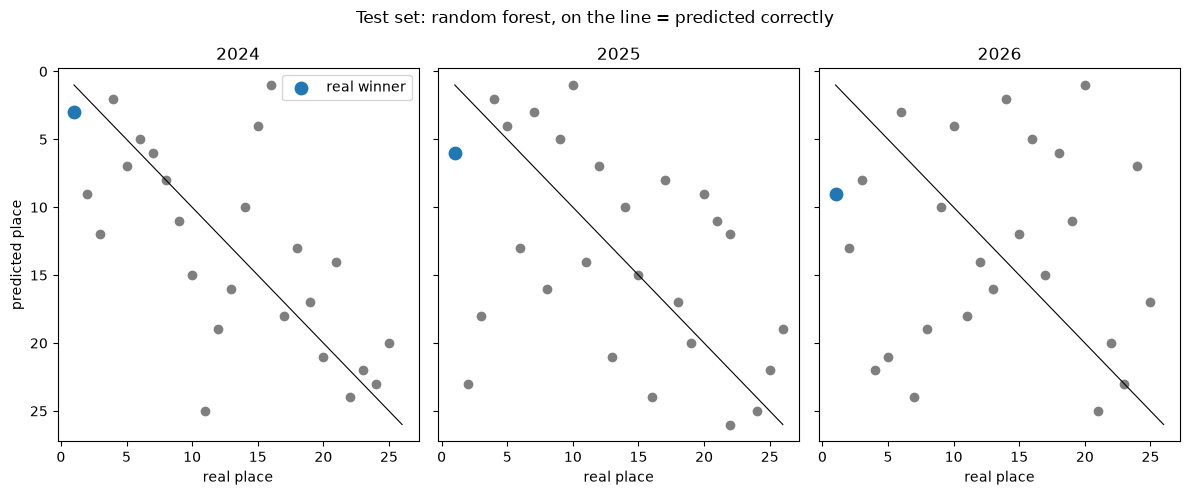

In [19]:
fig, axes = plt.subplots(1, len(TEST), figsize=(12, 5), sharey=True)
for ax, year in zip(axes, TEST):
    songs = board[board["year"] == year]
    winner = songs[songs["real place"] == 1]
    ax.scatter(songs["real place"], songs["predicted place"], color="tab:gray")
    ax.scatter(winner["real place"], winner["predicted place"], color="tab:blue", s=80, label="real winner")
    ax.plot([1, 26], [1, 26], color="black", linewidth=0.8)
    ax.set_title(f"{year}")
    ax.set_xlabel("real place")
    ax.invert_yaxis()
axes[0].set_ylabel("predicted place")
axes[0].legend()
fig.suptitle(f"Test set: {best_name}, on the line = predicted correctly")
plt.tight_layout()
plt.show()

### The predicted top N
The model's top N songs of every test final. Blue is the predicted score, grey the real score, and the number at the end of each row is the song's real place. Change `N` to show more or fewer songs.

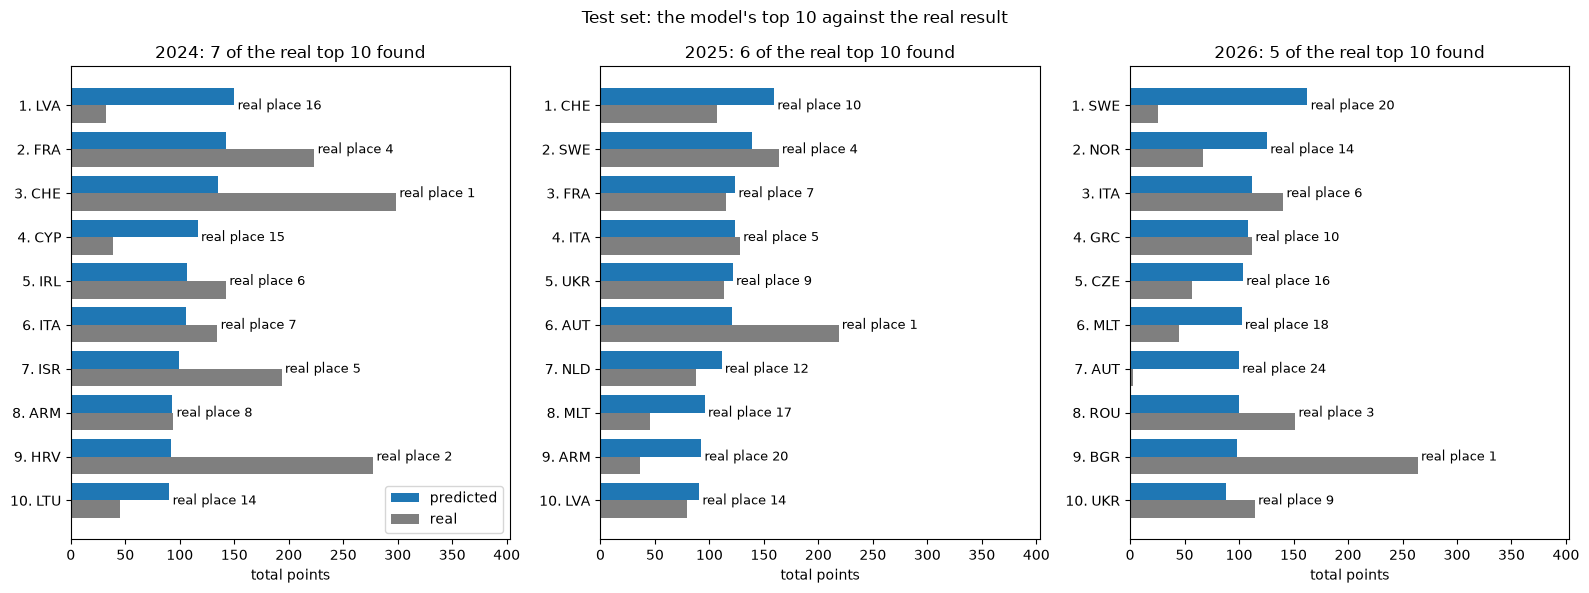

In [20]:
N = 10

fig, axes = plt.subplots(1, len(TEST), figsize=(16, 0.45 * N + 1.5))
for ax, year in zip(axes, TEST):
    songs = board[board["year"] == year].sort_values("predicted place").head(N)
    rows = np.arange(len(songs))
    ax.barh(rows - 0.2, songs["predicted"], height=0.4, color="tab:blue", label="predicted")
    ax.barh(rows + 0.2, songs["points"], height=0.4, color="tab:gray", label="real")
    for row, (_, song) in zip(rows, songs.iterrows()):
        ax.text(max(song["predicted"], song["points"]) + 3, row, f"real place {song['real place']}",
                va="center", fontsize=9)
    ax.set_yticks(rows, [f"{p}. {c}" for p, c in zip(songs["predicted place"], songs["to_iso3"])])
    ax.invert_yaxis()
    ax.set_xlim(0, board["points"].max() * 1.35)
    ax.set_xlabel("total points")
    found = (songs["real place"] <= N).sum()
    ax.set_title(f"{year}: {found} of the real top {N} found")
axes[0].legend(loc="lower right")
fig.suptitle(f"Test set: the model's top {N} against the real result")
plt.tight_layout()
plt.show()

## 9. Every final as a test year

Three test finals are few, one surprising winner changes a lot. As a check, every final from 2016 on is predicted once by a forest trained on **all earlier finals** only, like a real forecast the day before. Same settings as the best forest, missing values filled with the median of the earlier finals.

In [21]:
# X was filled with the medians of 2008-2019, refill with the earlier finals only
raw = X.copy()
raw[NUMERIC] = df[NUMERIC].astype(float)
for column in YES_NO:
    raw[column] = df[column].map({True: 1, False: 0, "True": 1, "False": 0}).astype(float)
yearly = []
for year in sorted(df.loc[df["year"] >= 2016, "year"].unique()):
    before, now = (df["year"] < year).to_numpy(), (df["year"] == year).to_numpy()
    filled = raw.fillna(raw[before].median())
    model = RandomForestRegressor(random_state=0, n_jobs=2, **best_params).fit(filled[before], y[before])
    predicted = model.predict(filled[now])
    yearly.append({"year": year,
                   "rank error": rank_error(now, predicted),
                   "chance": chance(now, draws=300)[0],
                   "winner predicted": winner_rank(now, predicted)[year]})
yearly = pd.DataFrame(yearly)
print(yearly.round(2).to_string(index=False))
print(f"\nmean over {len(yearly)} finals: model {yearly['rank error'].mean():.2f}, "
      f"chance {yearly['chance'].mean():.2f} places off")

 year  rank error  chance  winner predicted
 2016        4.50    8.59                 3
 2017        6.88    8.56                24
 2018        7.08    8.55                 4
 2019        6.65    8.72                 7
 2021        6.81    8.68                 3
 2022        5.40    8.30                 3
 2023        5.46    8.65                 2
 2024        5.52    8.31                 2
 2025        6.27    8.63                 3
 2026        7.60    8.37                 7

mean over 10 finals: model 6.22, chance 8.54 places off


## 10. Figures for the slides

Three figures, saved as PNG in `figures/` next to this notebook, with big fonts for the projector.

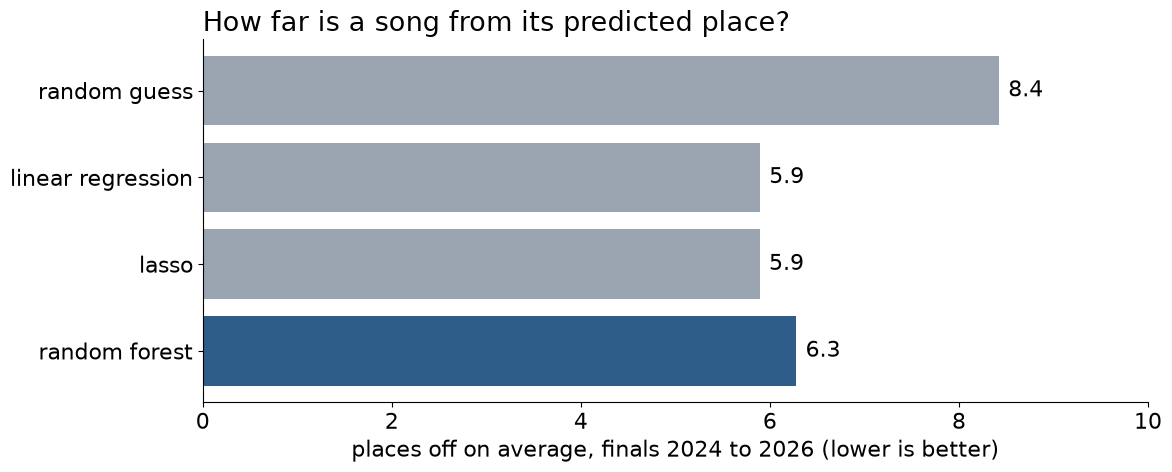

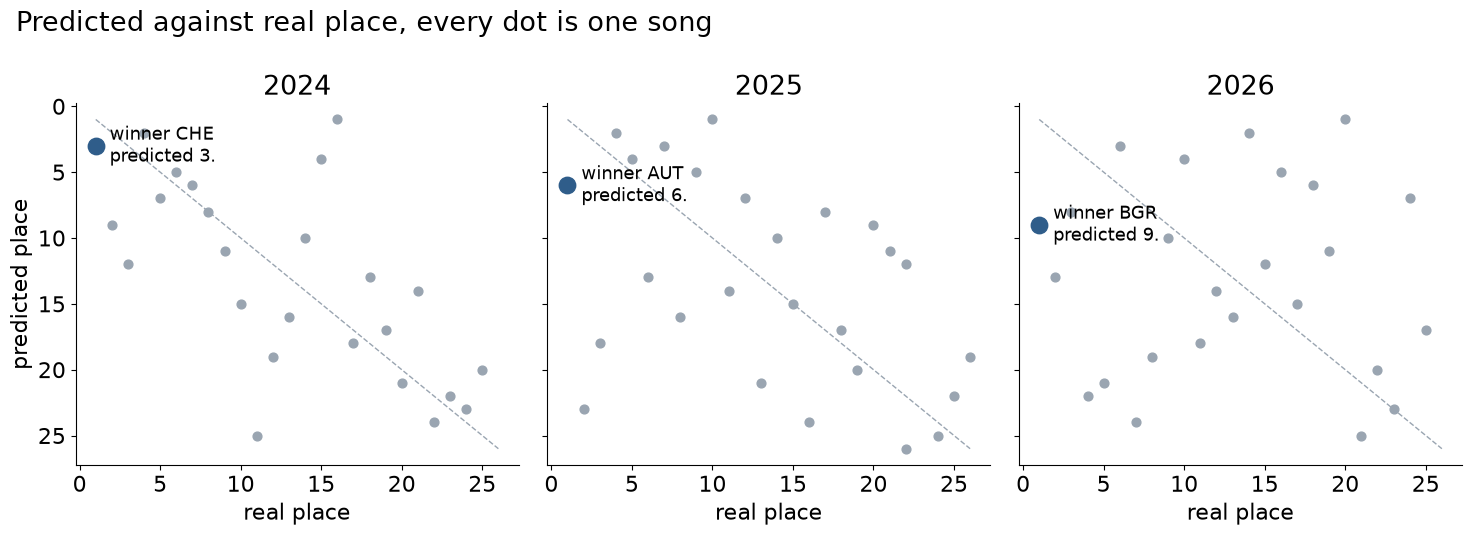

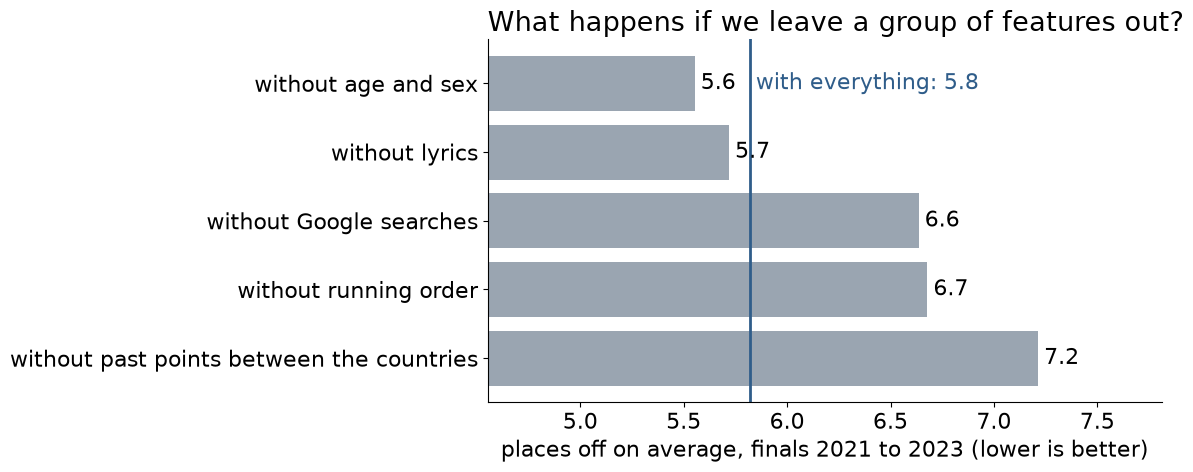

In [22]:
import os
os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"font.size": 16, "axes.spines.top": False, "axes.spines.right": False})
BLUE, GREY = "#2f5d8a", "#9aa5b1"

# slide 4: how good is the prediction
test_errors = {name: rank_error(test, best[name][0].predict(best[name][2]))
               for name in ["linear regression", "lasso", "random forest"]}
bars = [("random guess", chance(test)[0])] + list(test_errors.items())
fig, ax = plt.subplots(figsize=(12, 5))
ax.barh([b[0] for b in bars][::-1], [b[1] for b in bars][::-1],
        color=[BLUE if b[0] == "random forest" else GREY for b in bars][::-1])
for row, (_, value) in enumerate(bars[::-1]):
    ax.text(value + 0.1, row, f"{value:.1f}", va="center")
ax.set_xlim(0, 10)
ax.set_xlabel("places off on average, finals 2024 to 2026 (lower is better)")
ax.set_title("How far is a song from its predicted place?", loc="left")
fig.tight_layout()
fig.savefig("figures/slide-4-how-good.png", dpi=150)
plt.show()

# slide 5: predicted against real place, the winner highlighted
fig, axes = plt.subplots(1, len(TEST), figsize=(15, 5.5), sharey=True)
for ax, year in zip(axes, TEST):
    songs = board[board["year"] == year]
    winner = songs[songs["real place"] == 1].iloc[0]
    ax.plot([1, 26], [1, 26], color=GREY, linewidth=1, linestyle="--")
    ax.scatter(songs["real place"], songs["predicted place"], color=GREY, s=40)
    ax.scatter([winner["real place"]], [winner["predicted place"]], color=BLUE, s=140, zorder=3)
    ax.annotate(f"winner {winner['to_iso3']}\npredicted {winner['predicted place']}.",
                (winner["real place"], winner["predicted place"]), xytext=(10, 0),
                textcoords="offset points", va="center", fontsize=13)
    ax.set_title(str(year))
    ax.set_xlabel("real place")
    ax.invert_yaxis()
axes[0].set_ylabel("predicted place")
fig.suptitle("Predicted against real place, every dot is one song", x=0.02, ha="left")
fig.tight_layout()
fig.savefig("figures/slide-5-predicted-vs-real.png", dpi=150)
plt.show()

# slide 6: what helps, from the validation check
everything = ablation.loc["nothing (all features)", "val rank error"]
helps = ablation["val rank error"].drop("nothing (all features)").sort_values()
fig, ax = plt.subplots(figsize=(12, 5))
ax.barh([f"without {name}" for name in helps.index][::-1], helps.values[::-1], color=GREY)
ax.axvline(everything, color=BLUE, linewidth=2)
ax.text(everything + 0.03, len(helps) - 1, f"with everything: {everything:.1f}", color=BLUE, va="center")
for row, value in enumerate(helps.values[::-1]):
    ax.text(value + 0.03, row, f"{value:.1f}", va="center")
ax.set_xlim(min(helps.min(), everything) - 1, helps.max() + 0.6)
ax.set_xlabel("places off on average, finals 2021 to 2023 (lower is better)")
ax.set_title("What happens if we leave a group of features out?", loc="left")
fig.tight_layout()
fig.savefig("figures/slide-6-what-helps.png", dpi=150)
plt.show()

## 11. Summary

### All columns of `features_full.csv`

| column | meaning | used? |
|---|---|---|
| `points` | points the voting country gave this song (0–12), from 2016 the average of jury and public | **target** |
| `year`, `entry_id`, `from_iso3`, `to_iso3` | which final, which song, who votes, who receives | no, identify the row |
| `vote_type` | jury, public or combined | no, gone after averaging jury and public |
| `log_dist` | logarithm of the distance between the two countries | yes |
| `dist`, `distw` | the same distance without the logarithm | no, duplicate of `log_dist` |
| `contig` | the two countries share a border | yes |
| `comlang_off` | they share an official language | yes |
| `comlang_ethno` | a language spoken by at least 9 % in both | yes |
| `colony`, `comcol`, `smctry` | colonial link, same former colonizer, once the same country | yes |
| `past_points` | average points this pair gave each other in earlier finals | yes |
| `past_meetings` | how many earlier finals this pair met in | yes |
| `web_interest` | Google web searches for the song in the voting country before the final (0–100) | yes |
| `youtube_interest` | the same for YouTube searches | yes |
| `censored` | both search values are 0, the search volume was too small to measure | yes |
| `running_position` | the song's place in the running order | yes |
| `artist_age` | age of the solo artist at the final (bands have none) | yes |
| `artist_sex` | female, male, other, or band/unknown | yes |
| `sentiment` | mood of the lyrics: neutral, sad, funny | yes |
| `theme` | theme of the lyrics: romance, heartbreak, society, … | yes |
| `repetition_verse`, `repetition_chorus` | the lyrics repeat a lot | yes |
| `receiver_effect`, `points_received_total`, `points_share` | computed from the points of this final | no, unknown before the final |
| `round`, `jury_share`, `televote_share`, `separately_reported`, `row_vote` | voting rules of the year, the same for every song of a final | no, cannot tell songs apart |

### Removed as useless (12 features)
Lasso set them to 0 **and** the forest uses them less than 1 %:

- **Lyrics:** the themes romance, festivity, society, kinship, the funny mood, verse repetition, and the "unknown" mood and theme (only 2010, which has no lyrics)
- **Artist:** band or unknown
- **Country pair:** a commonly spoken language (`comlang_ethno`), same former colonizer (`comcol`)
- **Search:** `youtube_interest` (web search carries the same information)

Removing them changes almost nothing (validation R² 0.180 → 0.178 for the forest, 0.125 → 0.125 for lasso). So they really were not helping.

### Results

| model | validation R² | validation rank error | real winner's predicted place 2021 / 2022 / 2023 |
|---|---|---|---|
| chance | | 8.57 | |
| linear regression | 0.065 | 7.25 | 4 / 9 / 12 |
| **random forest** (no depth limit, at least 100 rows per leaf, 100 trees) | **0.180** | **5.82** | **3 / 3 / 2** |
| lasso | 0.125 | 6.91 | 5 / 6 / 5 |

- **Best model on validation: random forest**, tested once on 2024–2026: **6.28 places off** on average, chance 8.42 (95 % range 7.16 to 9.57). Test R² 0.121.
- **Honest note on the test finals:** there linear regression and lasso are slightly better in places (5.9 each, slide 4), although their R² is lower. The forest was chosen before looking at the test set, so we keep it. With three test finals the difference of 0.4 places is within chance. The real winners were predicted **3rd** (Switzerland 2024), **6th** (Austria 2025) and **9th** (Bulgaria 2026).
- **Every final as a test year** (section 9, trained only on earlier finals): 6.22 places off over ten finals against 8.54 for chance. The winner was in the predicted top 3 in six of ten finals. 2017 (Portugal, predicted 24th) was the big miss.
- **What helps:** past points between the two countries most, then Google searches and the running order. The years 2008–2015 help (7.12 → 5.82). Age, sex and lyrics make no reliable difference.
- **The forest needs large leaves.** The best settings all have at least 100 rows per leaf. Small leaves make the trees memorise single votes.

### For the slides (3 minutes in total, so about one sentence per slide)

- **Slide 4**, `figures/slide-4-how-good.png`: "Our models put a song about six places away from where it really ends up. A random guess is more than eight places off."
- **Slide 5**, `figures/slide-5-predicted-vs-real.png`: "It never picked the winner, but it put the real winner third, sixth and ninth. Over ten finals the winner was in its top three six times."
- **Slide 6**, `figures/slide-6-what-helps.png`: "What predicts the votes best is how two countries voted for each other before, then Google searches and the running order. The artist's age and sex and the lyrics do not help."